In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.GELU()
        )

    def forward(self, x):
        return self.block(x)



class ShipGeometryEncoder(nn.Module):

    def __init__(self, latent_dim=512):
        super().__init__()

        self.features = nn.Sequential(
            ConvBlock(1, 32),       # 256 -> 128
            ConvBlock(32, 64),      # 128 -> 64
            ConvBlock(64, 128),     # 64 -> 32
            ConvBlock(128, 256),    # 32 -> 16
            ConvBlock(256, 512)     # 16 -> 8
        )

        self.flatten = nn.Flatten()

        self.fc = nn.Linear(
            512 * 8 * 8,
            latent_dim
        )

    def forward(self, x):

        feature_map = self.features(x)

        z = self.fc(
            self.flatten(feature_map)
        )

        return z, feature_map


class ShipGeometryDecoder(nn.Module):

    def __init__(self, latent_dim=512):
        super().__init__()

        self.fc = nn.Linear(
            latent_dim,
            512 * 8 * 8
        )

        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                512, 256, 4, 2, 1
            ),
            nn.GroupNorm(8, 256),
            nn.GELU(),

            nn.ConvTranspose2d(
                256, 128, 4, 2, 1
            ),
            nn.GroupNorm(8, 128),
            nn.GELU(),

            nn.ConvTranspose2d(
                128, 64, 4, 2, 1
            ),
            nn.GroupNorm(8, 64),
            nn.GELU(),

            nn.ConvTranspose2d(
                64, 32, 4, 2, 1
            ),
            nn.GroupNorm(8, 32),
            nn.GELU(),

            nn.ConvTranspose2d(
                32, 1, 4, 2, 1
            ),

            nn.Sigmoid()
        )

    def forward(self, z):

        x = self.fc(z)

        x = x.view(-1, 512, 8, 8)

        return self.decoder(x)


class ShipGeometryAutoencoder(nn.Module):

    def __init__(self, latent_dim=512):
        super().__init__()

        self.encoder = ShipGeometryEncoder(latent_dim)
        self.decoder = ShipGeometryDecoder(latent_dim)

    def forward(self, x):

        z, feature_map = self.encoder(x)

        reconstructed = self.decoder(z)

        return reconstructed, z, feature_map

In [2]:
import torch

x = torch.rand(1, 1, 256, 256)

encoder = ShipGeometryEncoder(latent_dim=512)
decoder = ShipGeometryDecoder(latent_dim=512)

encoder.eval()

with torch.no_grad():
    z, feature_map = encoder(x)
    
print("Input:", x.shape)
print("Feature map:", feature_map.shape)
print("Latent vector:", z.shape)

with torch.no_grad():
    reconstructed = decoder(z)

print("Output:", reconstructed.shape)


Input: torch.Size([1, 1, 256, 256])
Feature map: torch.Size([1, 512, 8, 8])
Latent vector: torch.Size([1, 512])
Output: torch.Size([1, 1, 256, 256])


In [3]:
x = torch.rand(1, 1, 256, 256)

model = ShipGeometryAutoencoder(
    latent_dim=512
)
model.eval()

with torch.no_grad():
    reconstructed, z, feature_map = model(x)
    

print("Input:", x.shape)
print("Feature map:", feature_map.shape)
print("Latent vector:", z.shape)

with torch.no_grad():
    reconstructed = decoder(z)

print("Output:", reconstructed.shape)

Input: torch.Size([1, 1, 256, 256])
Feature map: torch.Size([1, 512, 8, 8])
Latent vector: torch.Size([1, 512])
Output: torch.Size([1, 1, 256, 256])


21


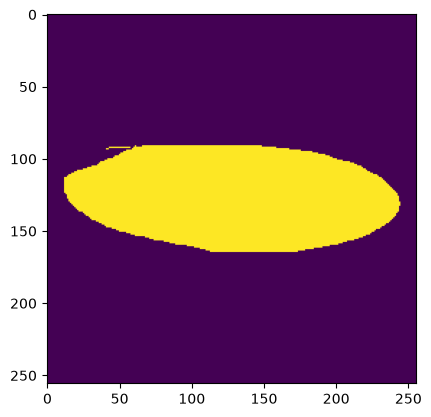

In [4]:
import os
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt


class ShipHullDataset(Dataset):

    def __init__(self, root_dir, image_size=256):
        self.image_dir = root_dir
        self.image_size = image_size

        self.image_files = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith(".png")
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):

        image_path = os.path.join(
            self.image_dir,
            self.image_files[idx]
        )

        # Load image as grayscale
        image = Image.open(image_path).convert("L")

        # Resize if necessary
        image = image.resize(
            (self.image_size, self.image_size)
        )

        # Convert to tensor [1, 256, 256]
        image = torch.from_numpy(
            __import__("numpy").array(image).copy()
        ).float() / 255.0

        # Ensure binary mask
        image = (image > 0.5).float()

        return image

root_dir = "data/img/train"
dataset = ShipHullDataset(root_dir)
img = dataset[0]
plt.imshow(img)
print(len(dataset))

In [5]:
def dice_loss(pred, target, eps=1e-7):

    pred = pred.flatten(start_dim=1)
    target = target.flatten(start_dim=1)

    intersection = (pred * target).sum(dim=1)

    dice = (
        2.0 * intersection + eps
    ) / (
        pred.sum(dim=1) + target.sum(dim=1) + eps
    )

    return 1.0 - dice.mean()

def reconstruction_loss(pred, target):

    bce = F.binary_cross_entropy(
        pred,
        target
    )

    dice = dice_loss(pred, target)

    return bce + dice

In [6]:
train_root_dir, test_root_dir = "data/img/train", "data/img/test"
train_dataset, test_dataset = ShipHullDataset(train_root_dir), ShipHullDataset(test_root_dir)
train_loader = DataLoader(train_dataset, batch_size=1)
test_loader  = DataLoader(test_dataset, batch_size=1)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = ShipGeometryAutoencoder(
    latent_dim=512
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

epochs = 100

# Early stopping parameters
patience = 10
best_test_loss = float("inf")
counter = 0
min_delta = 1e-5

def eval(model, test_loader):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.unsqueeze(0)
            images = batch.float().to(device)
            reconstructed, _, _ = model(images)
            loss = reconstruction_loss(
                reconstructed,
                images
            )
            total_loss += loss.item()
    return total_loss / len(test_loader)

train_losses, test_losses = [], []
for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    for batch in train_loader:
        batch = batch.unsqueeze(0)
        images = batch.float().to(device)
        optimizer.zero_grad()
        reconstructed, z, feature_map = model(images)
        loss = reconstruction_loss(
            reconstructed,
            images
        )
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    avg_test_loss = eval(model, test_loader)
    train_losses.append(avg_loss)
    test_losses.append(avg_test_loss)
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.5f} "
        f"Test Loss: {avg_test_loss:.5f}"
    )
    # Early stopping
    if avg_test_loss < best_test_loss - min_delta:

        best_test_loss = avg_test_loss
        counter = 0

        # Save best model
        torch.save(model.state_dict(), "best_model.pth")

        print(f"Validation loss improved: {best_test_loss:.5f}")

    else:
        counter += 1
        print(f"Early stopping counter: {counter}/{patience}")

    if counter >= patience:
        print(f"Early stopping triggered at epoch {epoch+1}")
        break

model.load_state_dict(torch.load("best_model.pth", map_location=device))

Epoch [1/100] Loss: 1.12612 Test Loss: 1.01291
Validation loss improved: 1.01291
Epoch [2/100] Loss: 0.81432 Test Loss: 0.78373
Validation loss improved: 0.78373
Epoch [3/100] Loss: 0.63230 Test Loss: 0.69228
Validation loss improved: 0.69228
Epoch [4/100] Loss: 0.53096 Test Loss: 0.60366
Validation loss improved: 0.60366
Epoch [5/100] Loss: 0.44169 Test Loss: 0.57381
Validation loss improved: 0.57381
Epoch [6/100] Loss: 0.39874 Test Loss: 0.52877
Validation loss improved: 0.52877
Epoch [7/100] Loss: 0.35923 Test Loss: 0.51280
Validation loss improved: 0.51280
Epoch [8/100] Loss: 0.32773 Test Loss: 0.51472
Early stopping counter: 1/10
Epoch [9/100] Loss: 0.28680 Test Loss: 0.48645
Validation loss improved: 0.48645
Epoch [10/100] Loss: 0.26072 Test Loss: 0.45738
Validation loss improved: 0.45738
Epoch [11/100] Loss: 0.23532 Test Loss: 0.47760
Early stopping counter: 1/10
Epoch [12/100] Loss: 0.22296 Test Loss: 0.46223
Early stopping counter: 2/10
Epoch [13/100] Loss: 0.19951 Test Loss: 

<All keys matched successfully>

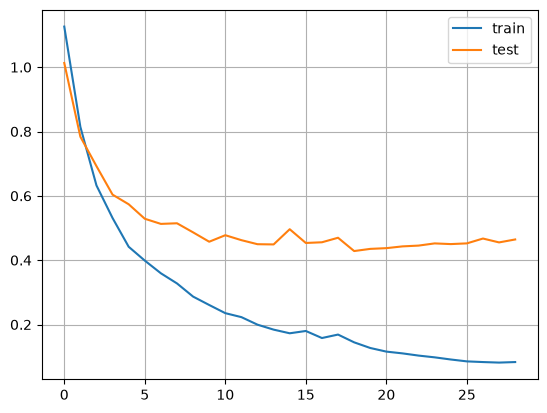

In [7]:
plt.plot(train_losses, label="train")
plt.plot(test_losses, label="test")
plt.grid()
plt.legend()

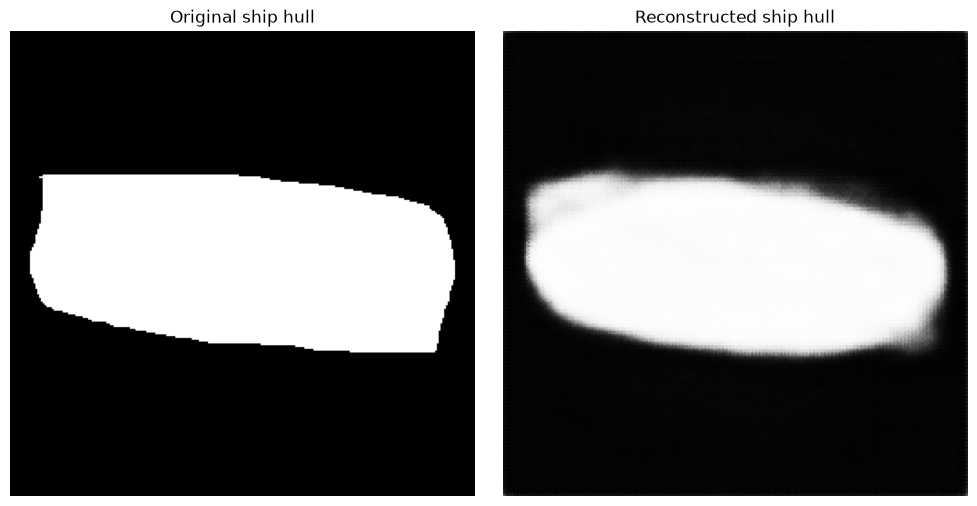

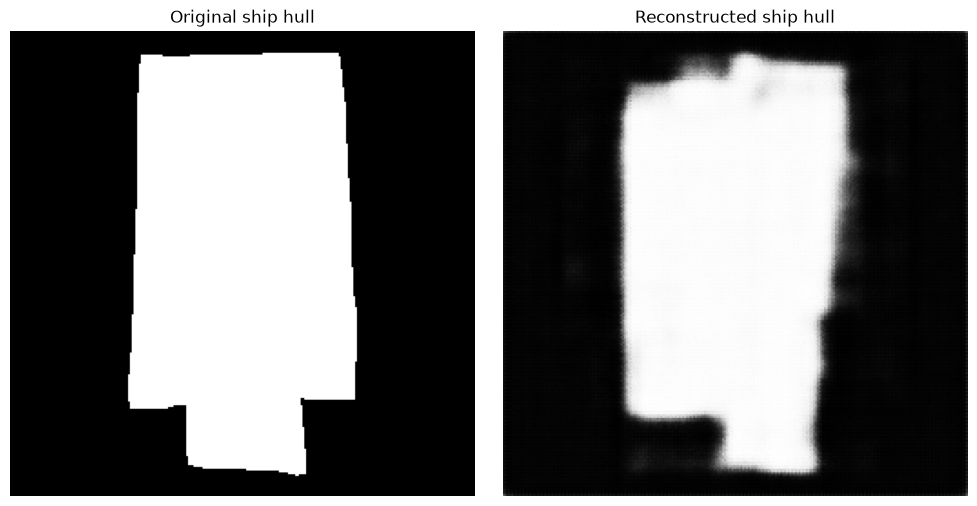

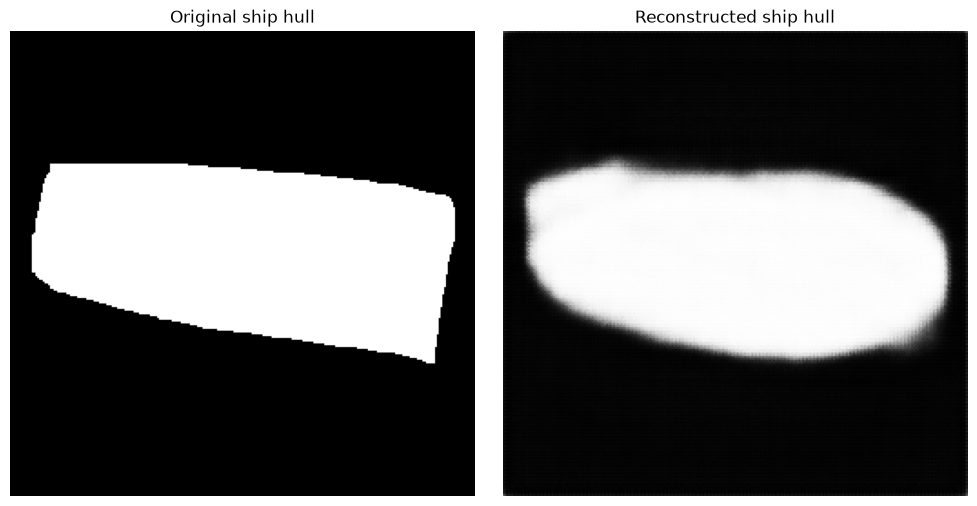

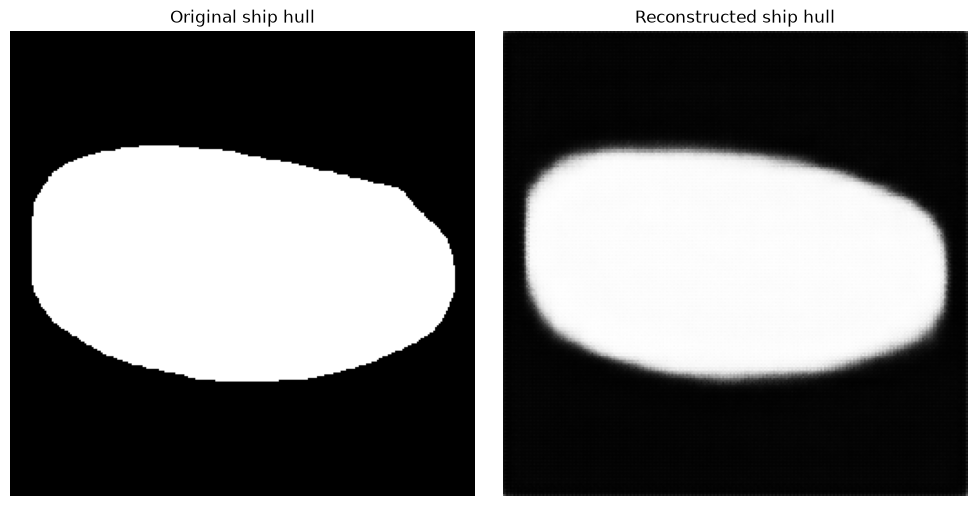

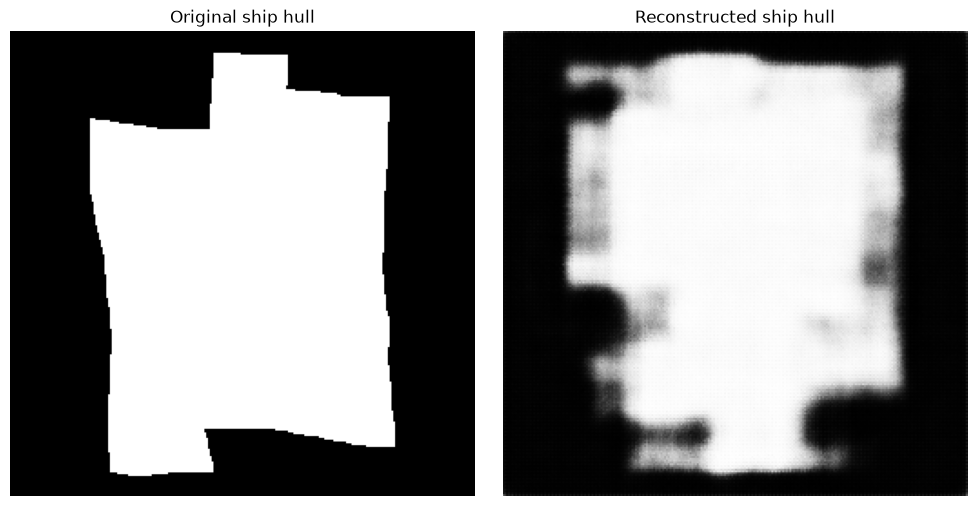

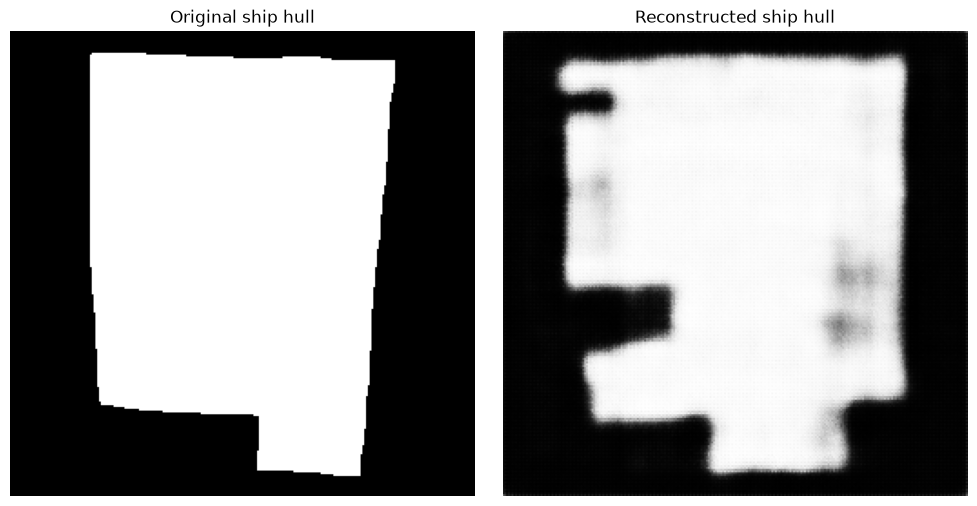

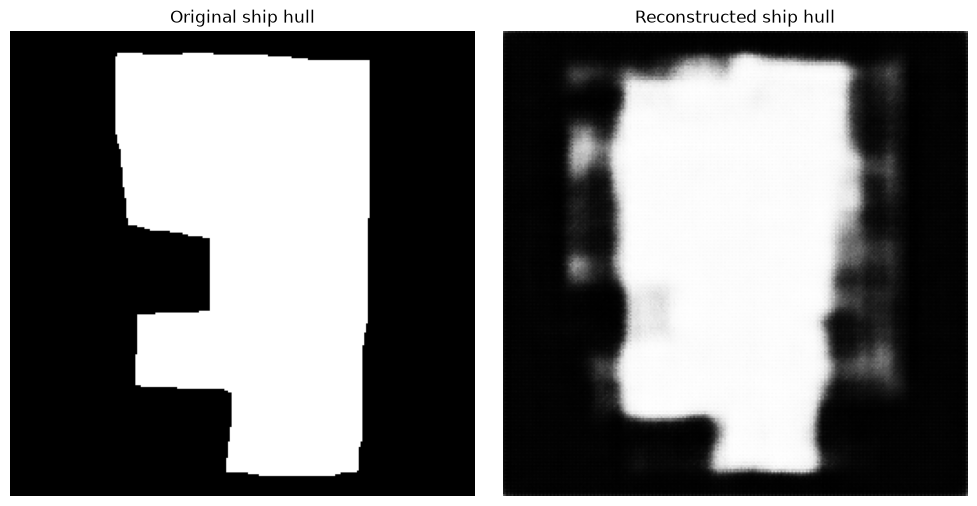

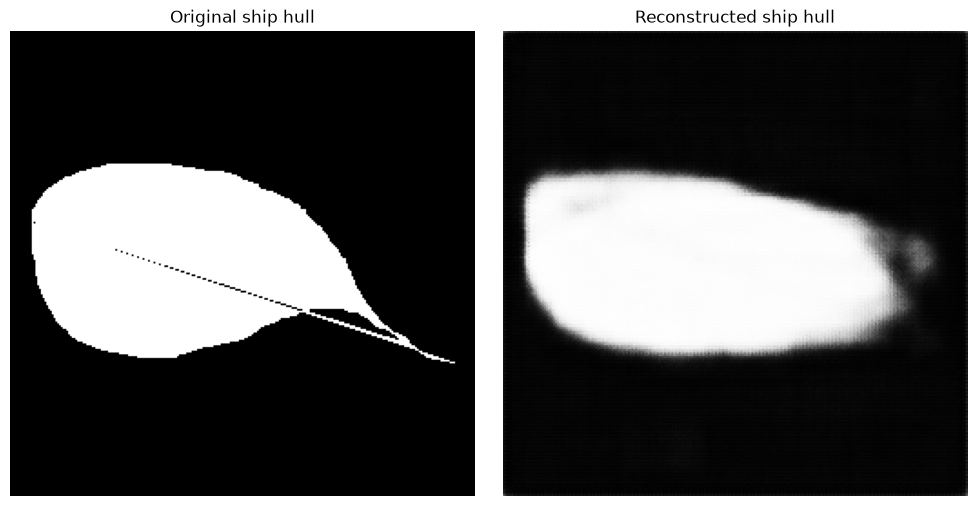

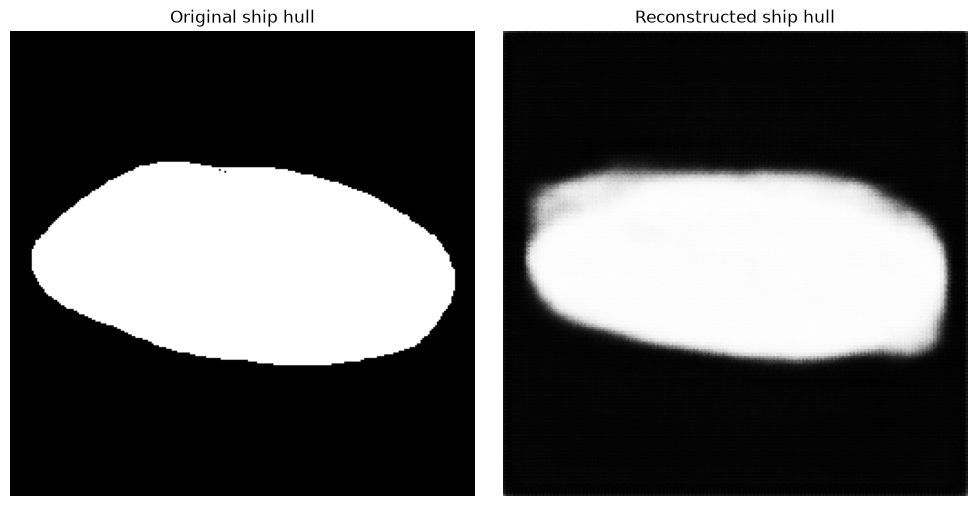

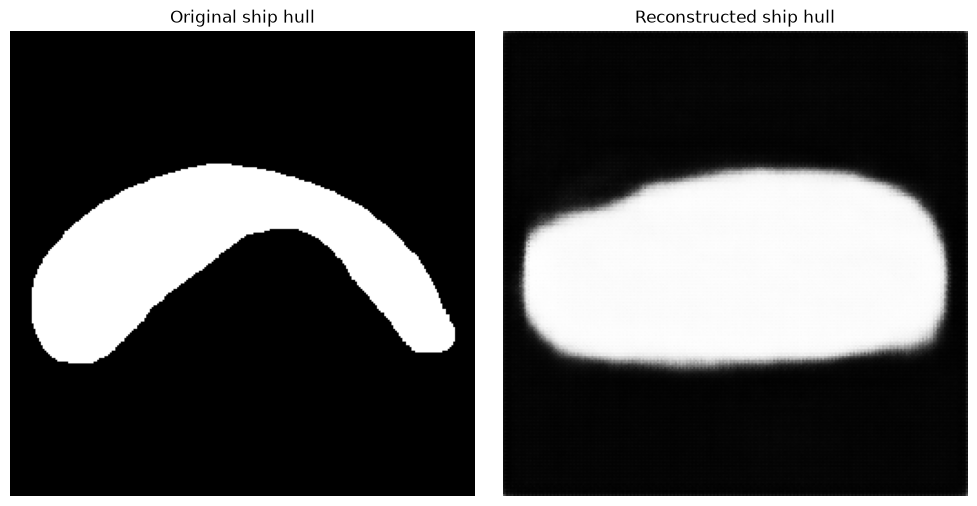

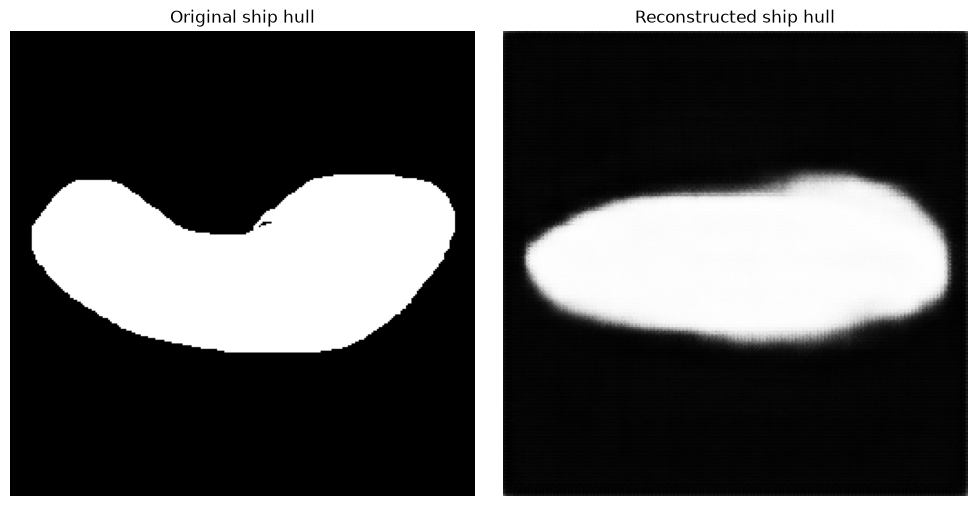

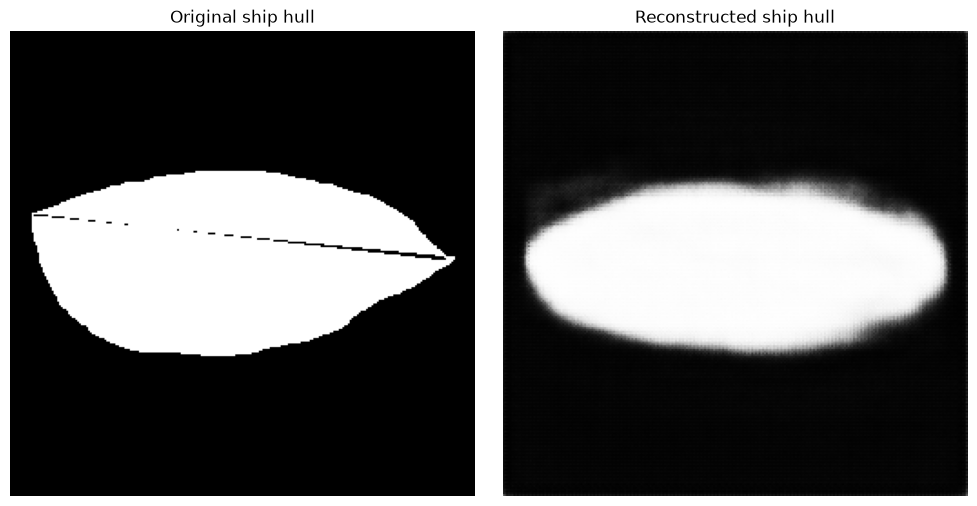

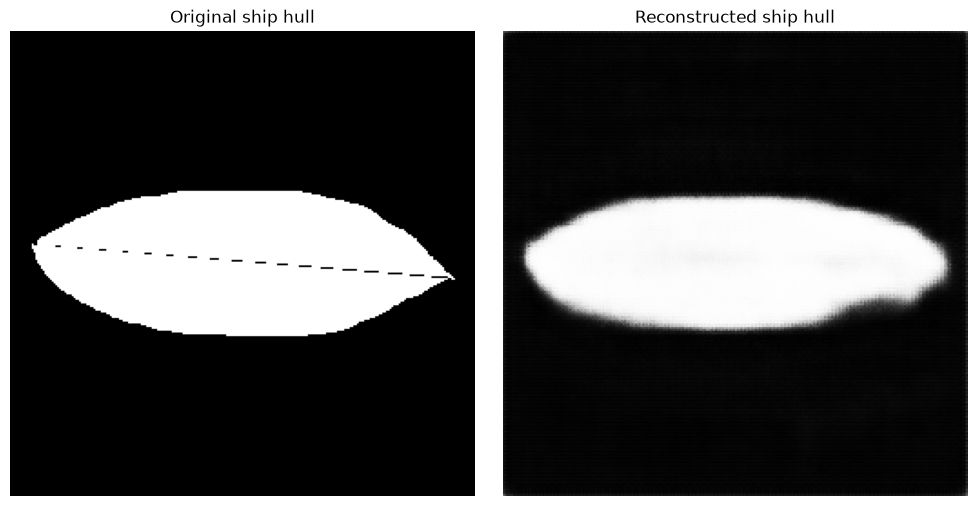

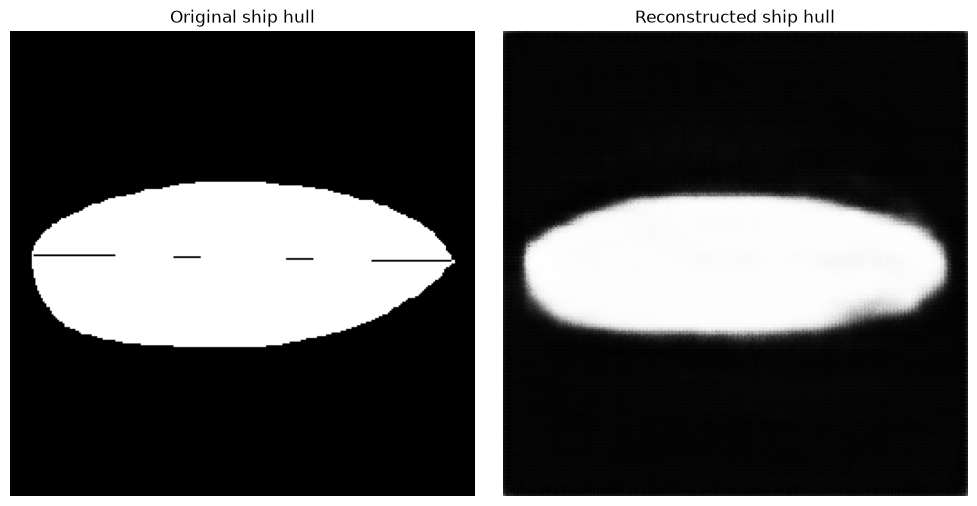

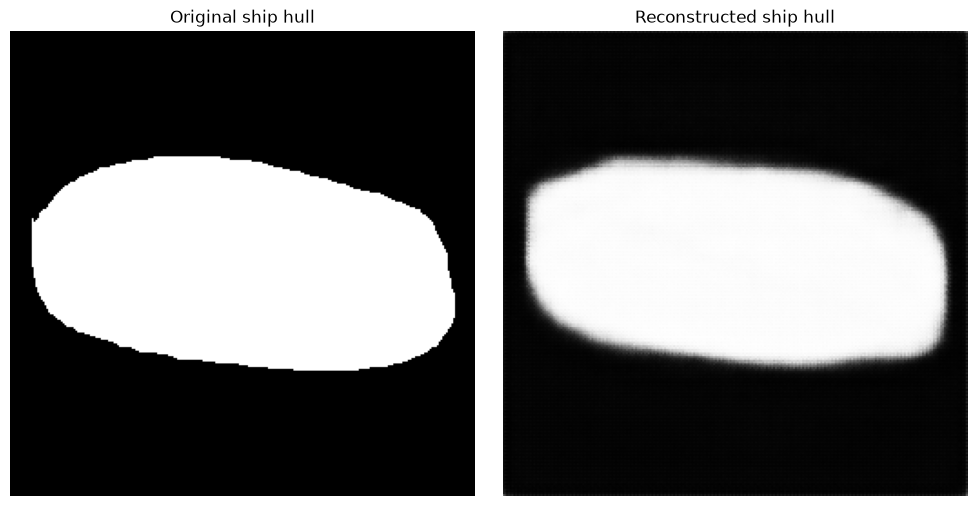

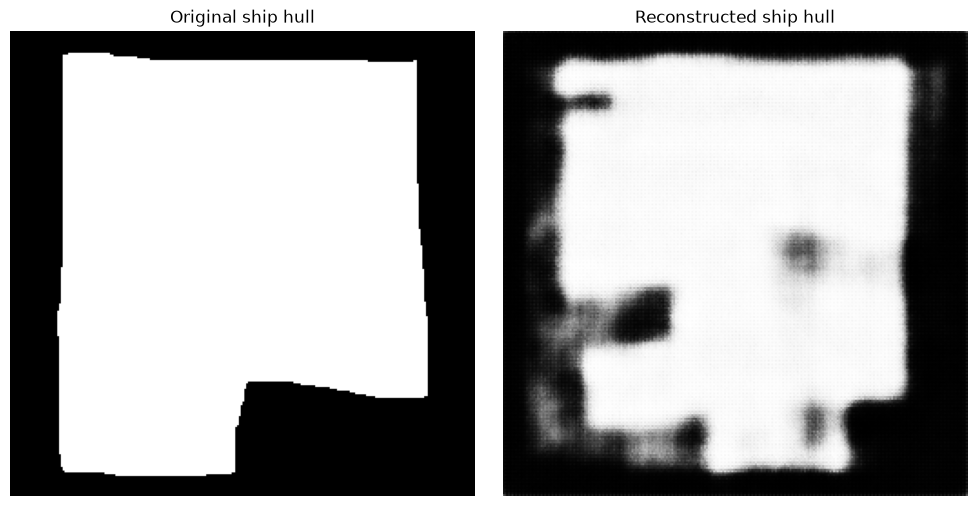

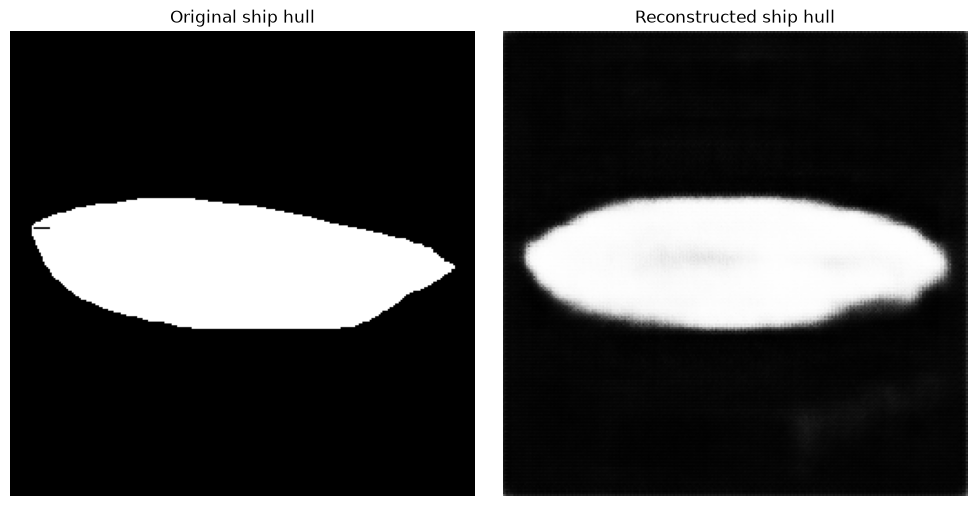

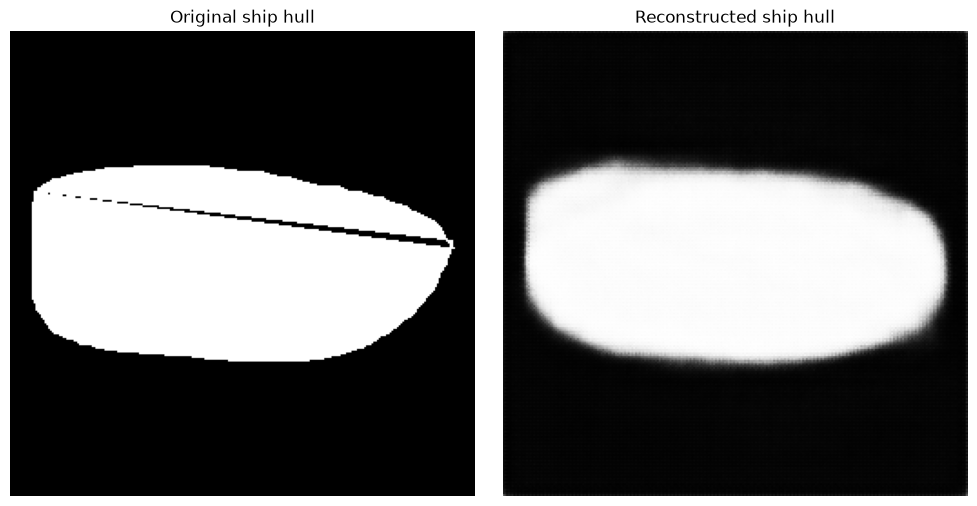

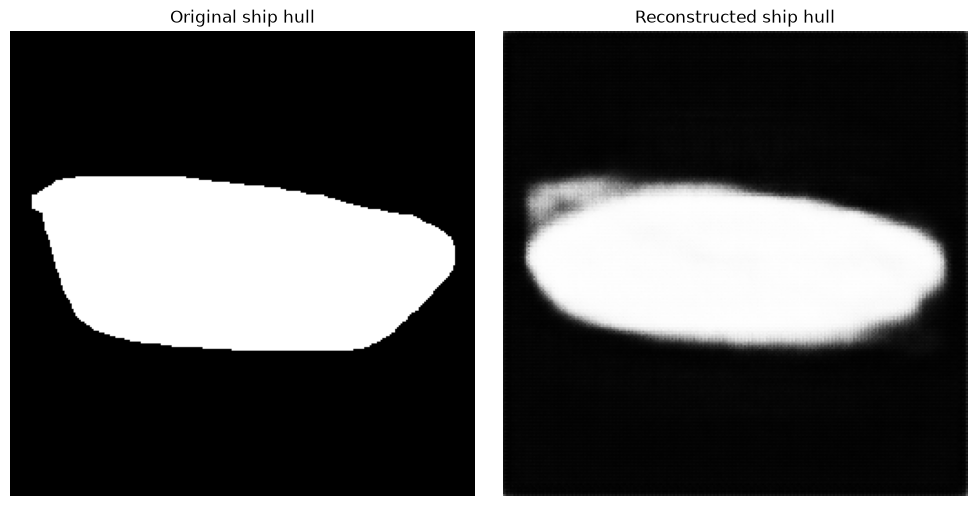

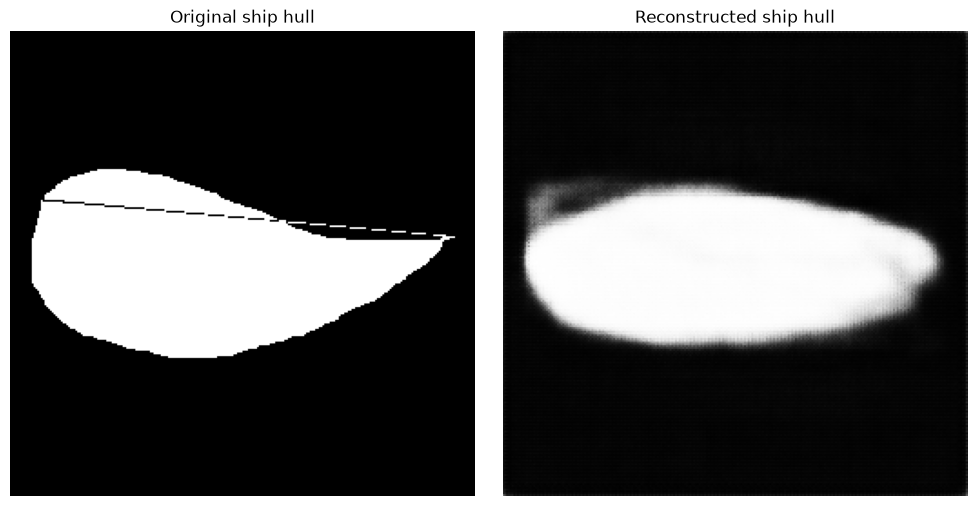

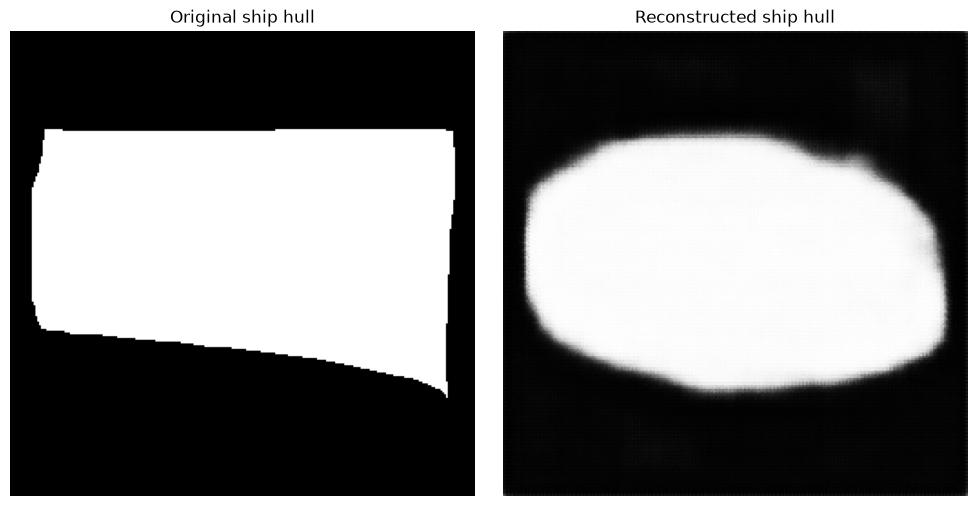

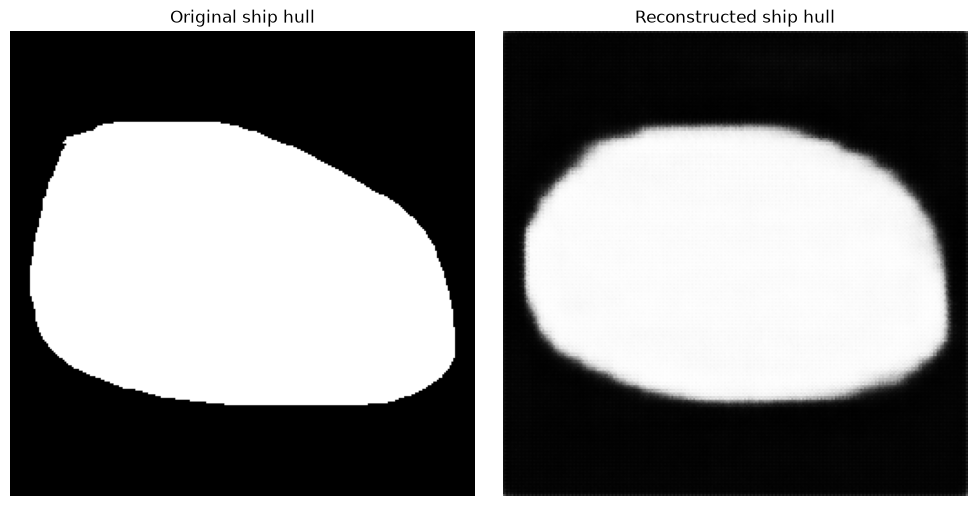

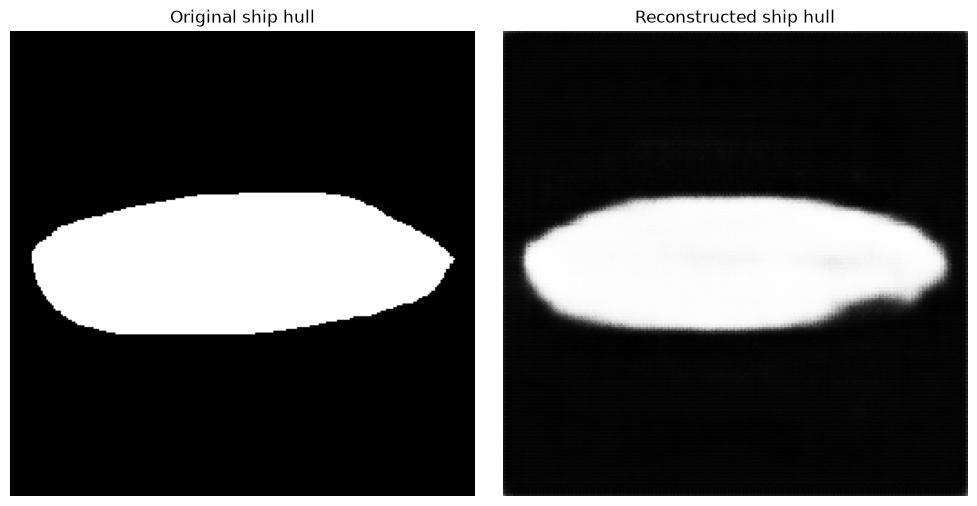

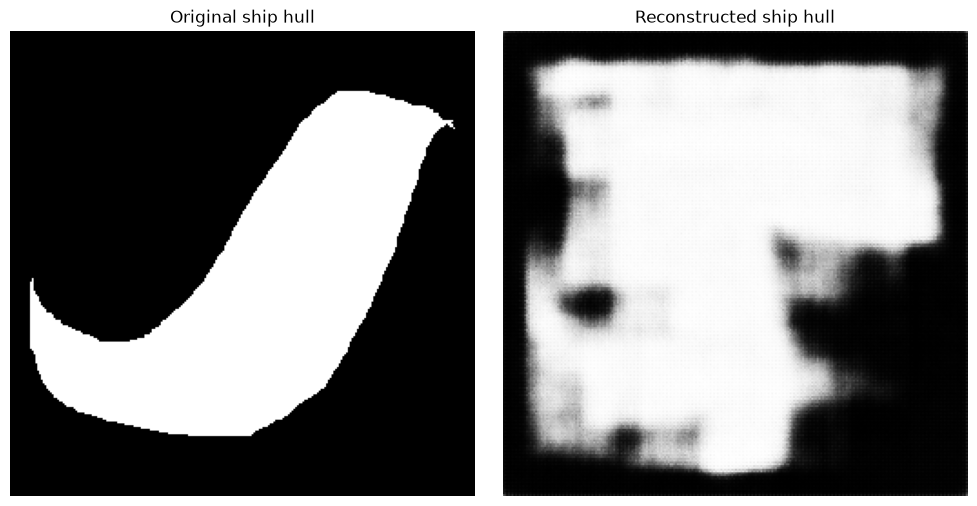

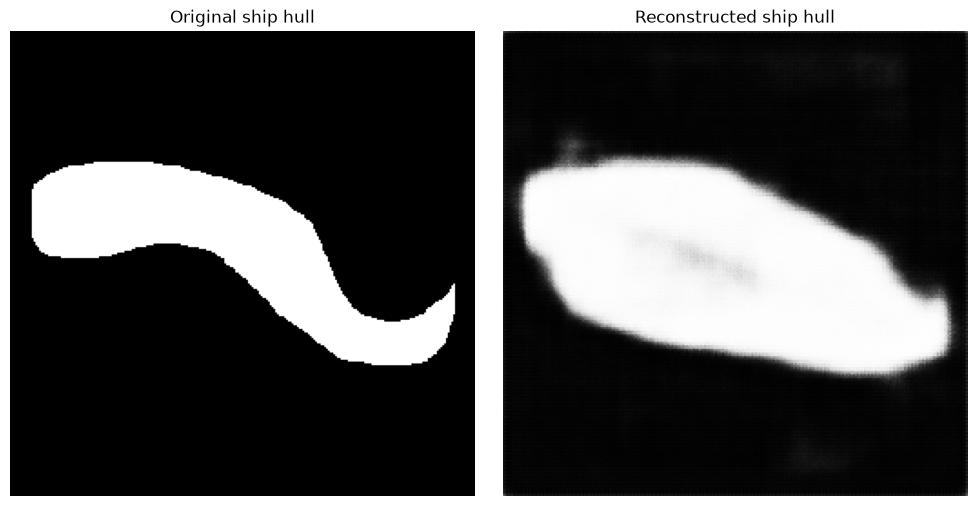

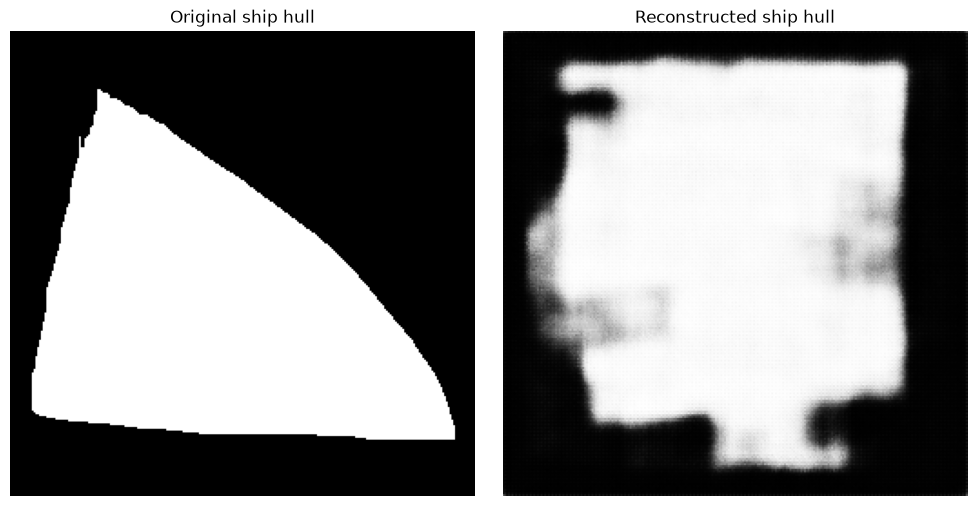

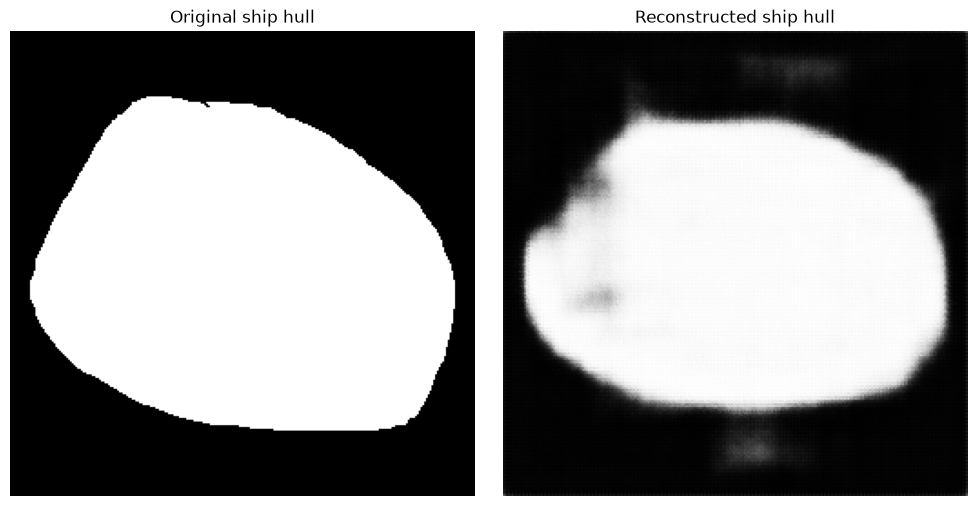

In [8]:
model.eval()
total_loss = 0
with torch.no_grad():
    for batch in test_loader:
        batch = batch.unsqueeze(0)
        images = batch.float().to(device)
        reconstructed, _, _ = model(images)
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(images[0].squeeze().cpu(), cmap="gray")
        axes[0].set_title("Original ship hull")
        axes[0].axis("off")

        # Reconstructed image
        axes[1].imshow(reconstructed.squeeze().cpu(), cmap="gray")
        axes[1].set_title("Reconstructed ship hull")
        axes[1].axis("off")

        plt.tight_layout()
        plt.show()
        